In [1]:
import pandas as pd
from pathlib import Path
from ucimlrepo import fetch_ucirepo 
import numpy as np
import matplotlib.pyplot as plt
import math
from matplotlib.patches import Rectangle, Patch

In [7]:
%pip install ucimlrepo

  Using cached ucimlrepo-0.0.7-py3-none-any.whl.metadata (5.5 kB)
Using cached ucimlrepo-0.0.7-py3-none-any.whl (8.0 kB)
Note: you may need to restart the kernel to use updated packages.


In [2]:
current_path = Path.cwd()

project_root = next(
    (p for p in [current_path, *current_path.parents]
     if (p / "README.md").exists()),
    None
)

if project_root is None:
    raise FileNotFoundError("Não foi encontrado nenhum README.md na hierarquia do projeto.")

raw_path = project_root / "data" / "raw"

raw_path.mkdir(parents=True, exist_ok=True)

csv_path = raw_path / "household_power_consumption.csv"

if csv_path.exists():
    print("Dataset já existente.")

else:
    individual_household_electric_power_consumption = fetch_ucirepo(id=235) 

    X = individual_household_electric_power_consumption.data.features 
    y = individual_household_electric_power_consumption.data.targets 

    df = X.copy()

    if y is not None:
        df = pd.concat([df, y], axis=1)
 

    df.to_csv(
        csv_path,
        index=False,
        sep=";",
        encoding="utf-8"
    )

    print("Dataset guardado com sucesso!")

Dataset já existente.


In [3]:
numero_eduardo = 54397
numero_felipe = 54698

ficheiro_bruto = Path("data/raw/household_power_consumption.csv")

soma_numeros_alunos = numero_eduardo + numero_felipe

rng = np.random.default_rng(soma_numeros_alunos)
inicio = pd.Timestamp(rng.choice(pd.date_range("2007-01-01", "2009-05-01", freq="MS")))
fim = inicio + pd.DateOffset(months=18)   
print(f"Janela do grupo: {inicio:%Y-%m-%d} → {fim:%Y-%m-%d} (18 meses)  | seed = {soma_numeros_alunos}")

Janela do grupo: 2007-10-01 → 2009-04-01 (18 meses)  | seed = 109095


In [4]:
def validar(df):

    assert isinstance(df.index, pd.DatetimeIndex)
    assert df.index.is_unique
    assert df.index.is_monotonic_increasing
    assert df["Voltage"].dropna().between(150, 300).all()
    assert (df["Global_intensity"].dropna() >= 0).all()

In [5]:
def carregar_dados(caminho=ficheiro_bruto, inicio=None, fim=None):

    df = pd.read_csv(caminho, sep=';', na_values="?",
                     low_memory=False)

    dt = pd.to_datetime(df.pop("Date") + " " + df.pop("Time"), format="%d/%m/%Y %H:%M:%S")
    df.index = pd.DatetimeIndex(dt, name="Datetime")
    df = df.sort_index()

    if inicio is not None and fim is not None:
        df = df.loc[(df.index >= inicio) & (df.index < fim)]

    validar(df)
    
    return df

df = carregar_dados(inicio=inicio, fim=fim)
print(df.head())

                     Global_active_power  Global_reactive_power  Voltage  \
Datetime                                                                   
2007-10-01 00:00:00                1.324                    0.0   239.04   
2007-10-01 00:01:00                1.320                    0.0   238.62   
2007-10-01 00:02:00                1.318                    0.0   238.56   
2007-10-01 00:03:00                1.320                    0.0   238.97   
2007-10-01 00:04:00                1.312                    0.0   238.32   

                     Global_intensity  Sub_metering_1  Sub_metering_2  \
Datetime                                                                
2007-10-01 00:00:00               5.4             0.0             0.0   
2007-10-01 00:01:00               5.4             0.0             0.0   
2007-10-01 00:02:00               5.4             0.0             0.0   
2007-10-01 00:03:00               5.4             0.0             0.0   
2007-10-01 00:04:00          

In [6]:
def analisar_valores_em_falta(df):

    mask = df.isnull()
    falta_qtd = mask.sum()
    falta_pct = (mask.mean() * 100).round(2)
    resumo = pd.DataFrame({"Valores em Falta": falta_qtd, "Percentagem (%)": falta_pct})

    print("\n=== ANÁLISE DE VALORES EM FALTA ===")
    resumo_com_falta = resumo[resumo["Valores em Falta"] > 0]
    if resumo_com_falta.empty:
        print("Não existem valores em falta no DataFrame.")
        return resumo
    print(resumo_com_falta)
    print(f"\nTotal geral de valores em falta: {falta_qtd.sum()}")

   
    ref = mask.iloc[:, 0]                                   
    iguais = mask.eq(ref, axis=0).all()                     
    alguma = mask.any(axis=1)                               
    todas = mask.all(axis=1)                                

    print(f"\nLinhas com alguma coluna em falta : {alguma.sum()}")
    print(f"Linhas com todas as colunas em falta: {todas.sum()}")
    if iguais.all():
        print("Os valores em falta coincidem exatamente nos mesmos instantes.")
    else:
        print("Os valores em falta não coincidem, há colunas que falham em instantes diferentes:")
        print(iguais[~iguais].index.tolist())
        print("Nº de colunas em falta por linha (só linhas com falta):")
        print(mask.sum(axis=1)[alguma].value_counts().sort_index().to_string())

    # --- Quando? Blocos de minutos consecutivos em falta (dia, hora de início e de fim) ---
    ts = df.index[alguma].to_series()
    bloco = (ts.diff() != pd.Timedelta(minutes=1)).cumsum()          # novo bloco quando há salto > 1 min
    blocos = ts.groupby(bloco).agg(inicio="min", fim="max", n_minutos="size").reset_index(drop=True)
    print(f"\n=== {len(blocos)} BLOCOS CONSECUTIVOS EM FALTA ===")
    display(blocos.sort_values("inicio"))
    print(f"\nDias distintos afetados: {ts.index.normalize().nunique()}")

    return resumo

resultado_faltas = analisar_valores_em_falta(df)


=== ANÁLISE DE VALORES EM FALTA ===
                       Valores em Falta  Percentagem (%)
Global_active_power                 207             0.03
Global_reactive_power               207             0.03
Voltage                             207             0.03
Global_intensity                    207             0.03
Sub_metering_1                      207             0.03
Sub_metering_2                      207             0.03
Sub_metering_3                      207             0.03

Total geral de valores em falta: 1449

Linhas com alguma coluna em falta : 207
Linhas com todas as colunas em falta: 207
Os valores em falta coincidem exatamente nos mesmos instantes.

=== 25 BLOCOS CONSECUTIVOS EM FALTA ===


,inicio,fim,n_minutos
0,2007-10-23 21:53:00,2007-10-23 21:54:00,2
1,2007-11-21 21:04:00,2007-11-21 21:04:00,1
2,2007-11-29 02:57:00,2007-11-29 02:57:00,1
3,2007-12-17 22:11:00,2007-12-17 22:11:00,1
4,2008-01-13 19:00:00,2008-01-13 19:00:00,1
5,2008-02-02 16:27:00,2008-02-02 16:27:00,1
6,2008-02-23 10:19:00,2008-02-23 10:20:00,2
7,2008-03-24 13:22:00,2008-03-24 13:22:00,1
8,2008-05-16 19:23:00,2008-05-16 19:24:00,2
9,2008-06-13 18:52:00,2008-06-13 18:52:00,1



Dias distintos afetados: 25


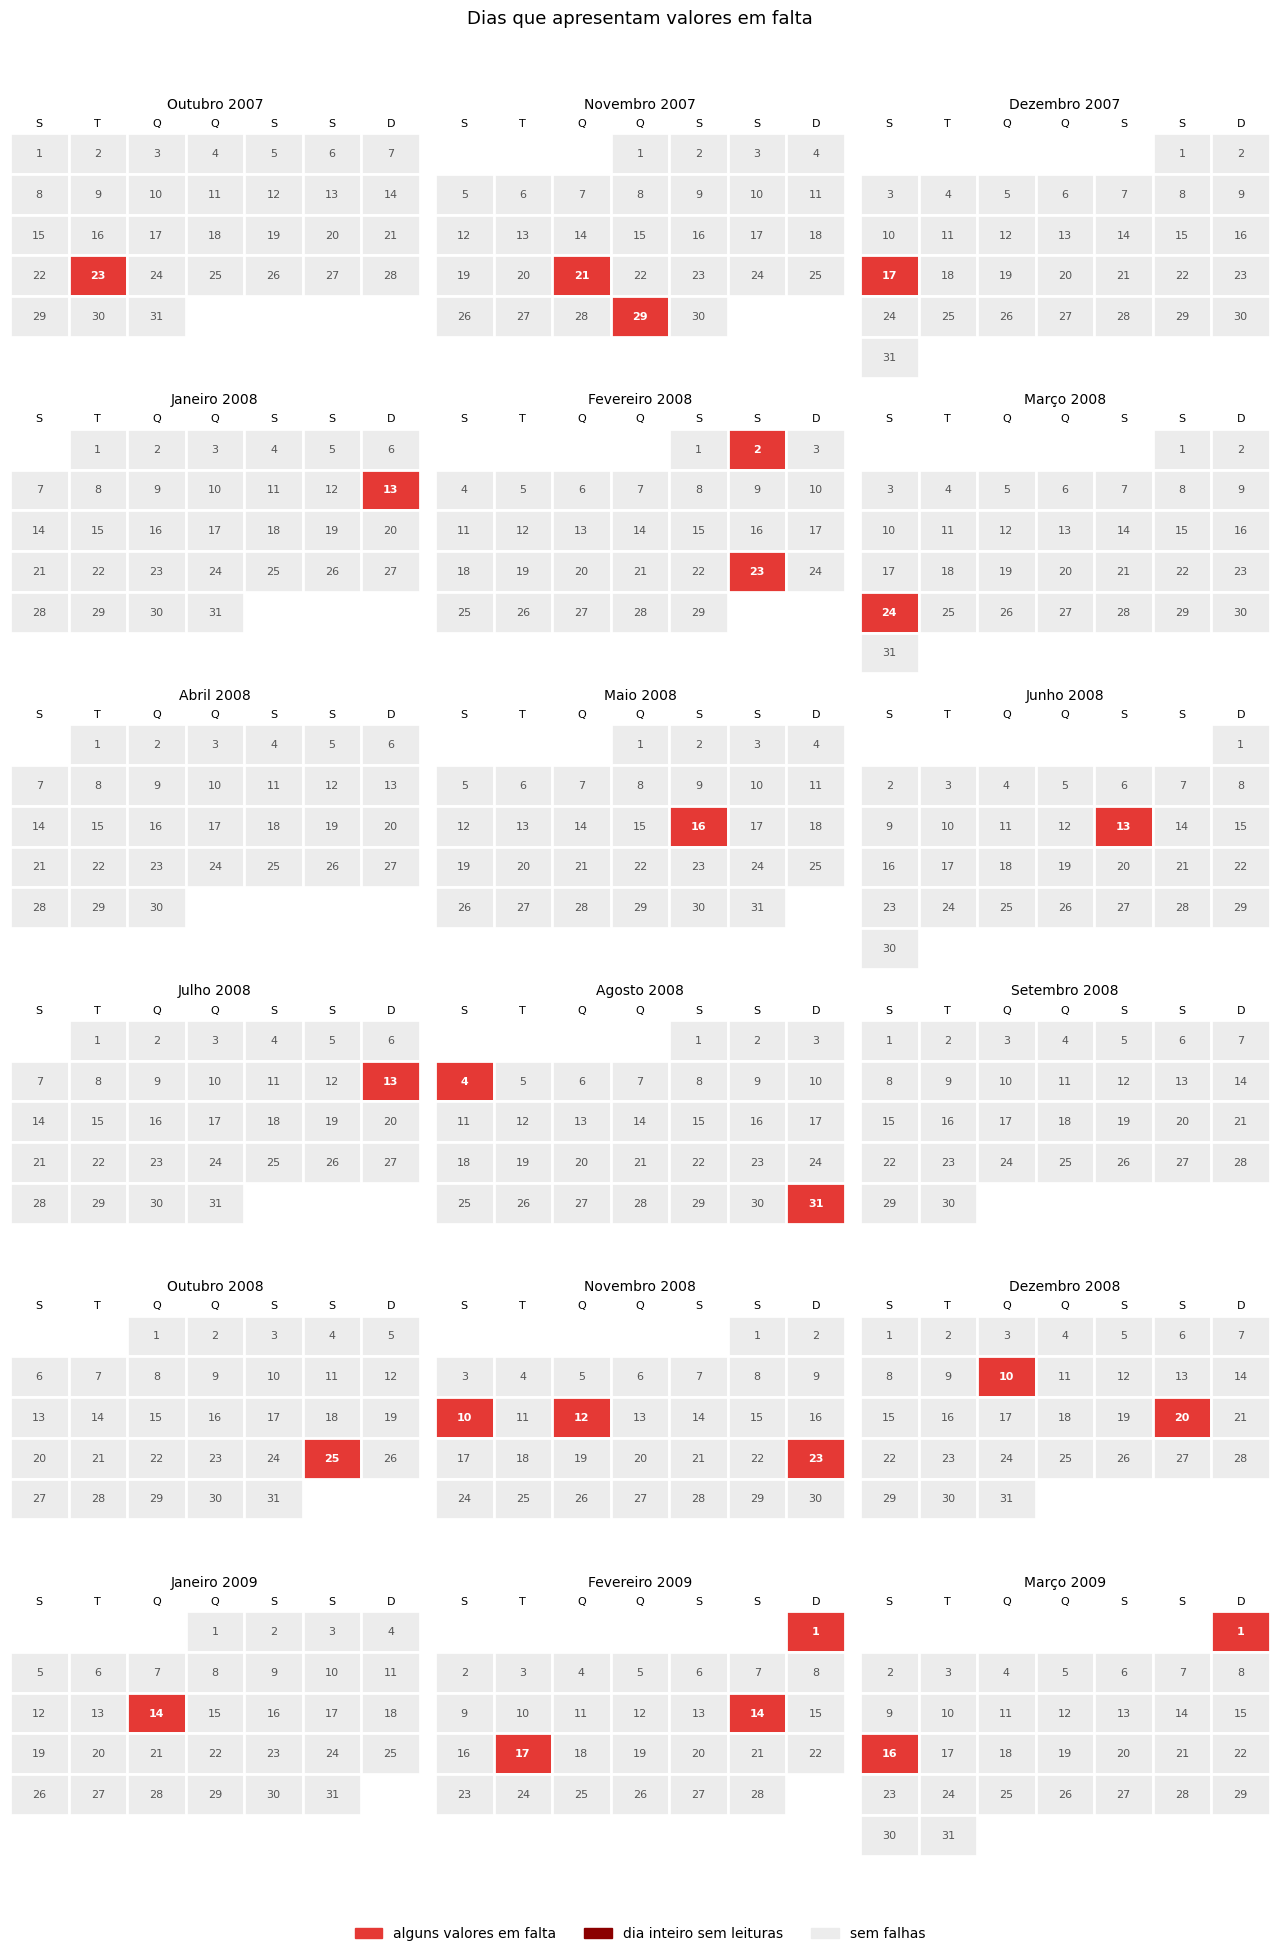

In [7]:
def grafico_calendario_missing(df, inicio, fim, colunas_por_linha=3):

    MESES = ["Janeiro", "Fevereiro", "Março", "Abril", "Maio", "Junho",
         "Julho", "Agosto", "Setembro", "Outubro", "Novembro", "Dezembro"]
    
    grelha = pd.date_range(inicio, fim - pd.Timedelta(minutes=1), freq="min")
    falta = df.reindex(grelha).isnull().any(axis=1)             
    minutos = falta.groupby(falta.index.normalize()).sum()       

    meses = pd.period_range(inicio, fim - pd.Timedelta(days=1), freq="M")
    nlin = math.ceil(len(meses) / colunas_por_linha)
    fig, axes = plt.subplots(nlin, colunas_por_linha, figsize=(4.3 * colunas_por_linha, 3.3 * nlin))
    axes = list(axes.ravel()) if hasattr(axes, "ravel") else [axes]

    for ax, mes in zip(axes, meses):
        primeiro = mes.start_time
        desloc = primeiro.weekday()                             
        for i in range(mes.days_in_month):
            dia = primeiro + pd.Timedelta(days=i)
            if dia < inicio.normalize() or dia >= fim:
                continue                                         
            lin, col = divmod(desloc + i, 7)
            m = minutos.get(dia, 0)
            cor = "#8b0000" if m >= 1440 else "#e53935" if m > 0 else "#ececec"
            ax.add_patch(Rectangle((col, lin), 1, 1, facecolor=cor, edgecolor="white", linewidth=2))
            ax.text(col + 0.5, lin + 0.5, str(dia.day), ha="center", va="center", fontsize=8,
                    color="white" if m > 0 else "#555555", fontweight="bold" if m > 0 else "normal")
        ax.set_xlim(0, 7); ax.set_ylim(6, 0)                    
        ax.set_xticks([i + 0.5 for i in range(7)], labels=list("STQQSSD"))
        ax.xaxis.tick_top(); ax.tick_params(length=0, labelsize=8)
        ax.set_yticks([])
        for lado in ax.spines.values():
            lado.set_visible(False)
        ax.set_title(f"{MESES[mes.month - 1]} {mes.year}", fontsize=10, pad=18)
    for ax in axes[len(meses):]:
        ax.axis("off")

    fig.suptitle("Dias que apresentam valores em falta", fontsize=13)
    fig.legend(handles=[Patch(color="#e53935", label="alguns valores em falta"),
                        Patch(color="#8b0000", label="dia inteiro sem leituras"),
                        Patch(color="#ececec", label="sem falhas")],
               loc="lower center", ncol=3, frameon=False)
    fig.tight_layout(rect=(0, 0.04, 1, 0.96))
    plt.show()

grafico_calendario_missing(df, inicio, fim)

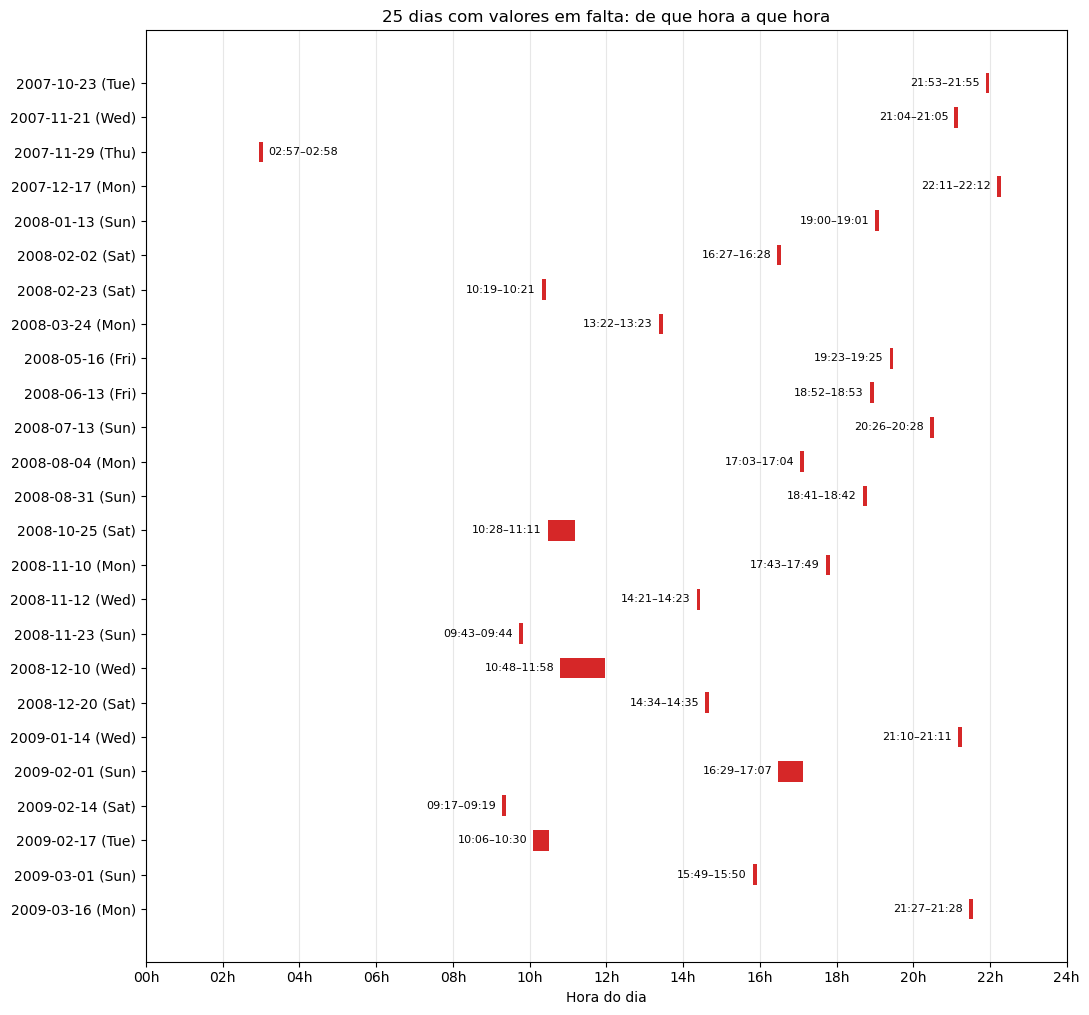

In [8]:
def grafico_missing(df, inicio, fim, col="Global_active_power"):
    
    grelha = pd.date_range(inicio, fim - pd.Timedelta(minutes=1), freq="min")
    falta = df[col].reindex(grelha).isna()           

    m = np.diff(np.concatenate(([0], falta.to_numpy().astype(np.int8), [0])))
    ini = grelha[np.flatnonzero(m == 1)]
    fi = grelha[np.flatnonzero(m == -1) - 1] + pd.Timedelta(minutes=1)

    segs = []
    for a, b in zip(ini, fi):
        for dia in pd.date_range(a.normalize(), (b - pd.Timedelta(minutes=1)).normalize(), freq="D"):
            s, e = max(a, dia), min(b, dia + pd.Timedelta(days=1))
            segs.append((dia, (s - dia).total_seconds() / 3600, (e - dia).total_seconds() / 3600))
    if not segs:
        print("Sem valores em falta na janela.")
        return
    dias = sorted({d for d, _, _ in segs})
    linha = {d: i for i, d in enumerate(dias)}

    def hhmm(h):
        mins = round(h * 60)
        return f"{mins // 60:02d}:{mins % 60:02d}"

    fig, ax = plt.subplots(figsize=(11, max(3, 0.35 * len(dias) + 1.5)))
    for d, x0, x1 in segs:
        y, w = linha[d], max(x1 - x0, 0.1)           
        ax.barh(y, w, left=x0, height=0.6, color="tab:red")
        txt = f"{hhmm(x0)}–{hhmm(x1)}"
        if w >= 4:                                   
            ax.text(x0 + w / 2, y, txt, va="center", ha="center", fontsize=8, color="white")
        elif x0 > 4:                                 
            ax.text(x0 - 0.15, y, txt, va="center", ha="right", fontsize=8)
        else:                                       
            ax.text(x0 + w + 0.15, y, txt, va="center", fontsize=8)
    ax.set_yticks(range(len(dias)), labels=[d.strftime("%Y-%m-%d (%a)") for d in dias])
    ax.invert_yaxis()
    ax.set_xlim(0, 24)
    ax.set_xticks(range(0, 25, 2), labels=[f"{h:02d}h" for h in range(0, 25, 2)])
    ax.set_xlabel("Hora do dia")
    ax.grid(axis="x", alpha=0.3)
    ax.set_title(f"{len(dias)} dias com valores em falta: de que hora a que hora")
    fig.tight_layout()
    plt.show()

grafico_missing(df, inicio, fim)

In [9]:
def tratar_missing(df, inicio, fim, seed, limite_curta_min=10, n_viz=10, n_semanas=10, colunas=None):
    """Tratamento de valores em falta com dois métodos, consoante a duração da lacuna (por coluna):

    - Lacuna CURTA (duração <= limite_curta_min):
        média e desvio padrão dos n_viz minutos antes e dos n_viz minutos depois da lacuna;
        cada minuto em falta recebe um valor aleatório uniforme em [média - dp, média + dp]
        (limite inferior cortado em 0: nenhuma variável pode ser negativa).
    - Lacuna LONGA (duração > limite_curta_min):
        cada minuto em falta recebe a média dos n_semanas valores anteriores e dos n_semanas valores
        seguintes do mesmo minuto e do mesmo dia da semana (±7, ±14, ... dias).

    Vizinhos que também estejam em falta são ignorados. Se não houver nenhum vizinho, o valor fica NaN.
    Devolve o DataFrame na grelha completa de 1 min + colunas 'imputado_curta', 'imputado_longa',
    'imputado' e 'sem_vizinhos'.
    """
    rng = np.random.default_rng(seed)                       # seed fixa -> resultados reprodutíveis
    grelha = pd.date_range(inicio, fim - pd.Timedelta(minutes=1), freq="min", name=df.index.name)
    g = df.reindex(grelha)                                  # inclui minutos que nem existem no ficheiro
    out = g.copy()
    colunas = list(g.columns) if colunas is None else list(colunas)
    n = len(g)
    passo_semana = 7 * 24 * 60                              # nº de linhas numa semana (grelha de 1 min)
    flag_curta, flag_longa = np.zeros(n, dtype=bool), np.zeros(n, dtype=bool)

    print(f"{'coluna':24s} {'em falta':>9s} {'curtas':>9s} {'longas':>9s} {'ainda NaN':>10s}")
    for col in colunas:
        x = g[col].to_numpy(dtype="float64")
        falta = np.isnan(x)
        if not falta.any():
            continue
        novo = x.copy()

        # lacunas = sequências consecutivas de NaN (run-length)
        d = np.diff(np.concatenate(([0], falta.astype(np.int8), [0])))
        ini, fim_ = np.flatnonzero(d == 1), np.flatnonzero(d == -1)        # fim_ é exclusivo
        dur = fim_ - ini

        # ---- 1) lacunas curtas: valor aleatório em [média - dp, média + dp] ----
        n_curta = 0
        for a, b in zip(ini[dur <= limite_curta_min], fim_[dur <= limite_curta_min]):
            viz = np.concatenate((x[max(a - n_viz, 0):a], x[b:b + n_viz]))   # n_viz antes + n_viz depois
            viz = viz[~np.isnan(viz)]
            if viz.size == 0:
                continue
            m = viz.mean()
            dp = viz.std(ddof=1) if viz.size > 1 else 0.0
            novo[a:b] = rng.uniform(max(m - dp, 0.0), m + dp, size=b - a)
            flag_curta[a:b] = True
            n_curta += b - a

        # ---- 2) lacunas longas: média dos mesmos minutos/dias da semana (±n_semanas semanas) ----
        longa = np.zeros(n, dtype=bool)
        for a, b in zip(ini[dur > limite_curta_min], fim_[dur > limite_curta_min]):
            longa[a:b] = True
        n_longa = 0
        if longa.any():
            soma, cont = np.zeros(n), np.zeros(n)
            for k in range(1, n_semanas + 1):
                for s in (k * passo_semana, -k * passo_semana):
                    if abs(s) >= n:
                        continue
                    viz = np.full(n, np.nan)
                    if s > 0:
                        viz[s:] = x[:-s]                    # valor k semanas antes
                    else:
                        viz[:s] = x[-s:]                    # valor k semanas depois
                    ok = ~np.isnan(viz)
                    soma[ok] += viz[ok]
                    cont[ok] += 1
            media = np.divide(soma, cont, out=np.full(n, np.nan), where=cont > 0)
            preencher = longa & ~np.isnan(media)
            novo[preencher] = media[preencher]
            flag_longa |= preencher
            n_longa = int(preencher.sum())

        out[col] = novo.astype(g[col].dtype)
        print(f"{col:24s} {falta.sum():9,d} {n_curta:9,d} {n_longa:9,d} {int(np.isnan(novo).sum()):10,d}")

    out["imputado_curta"], out["imputado_longa"] = flag_curta, flag_longa
    out["imputado"] = flag_curta | flag_longa
    out["sem_vizinhos"] = out[colunas].isna().any(axis=1)
    return out

df_tratado = tratar_missing(df, inicio, fim, soma_numeros_alunos)

coluna                    em falta    curtas    longas  ainda NaN
Global_active_power            207        32       175          0
Global_reactive_power          207        32       175          0
Voltage                        207        32       175          0
Global_intensity               207        32       175          0
Sub_metering_1                 207        32       175          0
Sub_metering_2                 207        32       175          0
Sub_metering_3                 207        32       175          0


Minutos observados (não imputados) em Global_active_power: 788,913 de 789,120
Regra: |assimetria| > 1 → distribuição muito assimétrica → mediana + IQR (robustos); senão média + dp.


,unidade,n,média,mediana,dp,MAD_norm,IQR,assimetria,curtose_exc,min,p1,p99,max,%zeros,recomendação
Global_active_power,kW,788913.0,1.154,0.678,1.115,0.703,1.272,1.740,3.915,0.076,0.082,5.102,11.122,0.000,mediana + IQR
Global_reactive_power,kVAr,788913.0,0.111,0.088,0.107,0.128,0.170,1.410,3.149,0.000,0.000,0.460,1.390,25.474,mediana + IQR
Voltage,V,788913.0,241.016,240.970,3.120,2.980,4.030,-0.057,0.285,224.580,233.360,248.270,253.940,0.000,média + dp
Global_intensity,A,788913.0,4.878,3.000,4.689,3.262,5.200,1.799,4.259,0.200,0.200,21.600,48.400,0.000,mediana + IQR
Sub_metering_1,Wh,788913.0,1.191,0.000,6.377,0.000,0.000,5.728,32.737,0.000,0.000,38.000,82.000,91.580,mediana + IQR
Sub_metering_2,Wh,788913.0,1.367,0.000,6.271,0.000,1.000,6.716,51.395,0.000,0.000,37.000,77.000,74.700,mediana + IQR
Sub_metering_3,Wh,788913.0,6.404,1.000,8.398,1.483,17.000,0.678,-1.416,0.000,0.000,19.000,31.000,47.344,média + dp


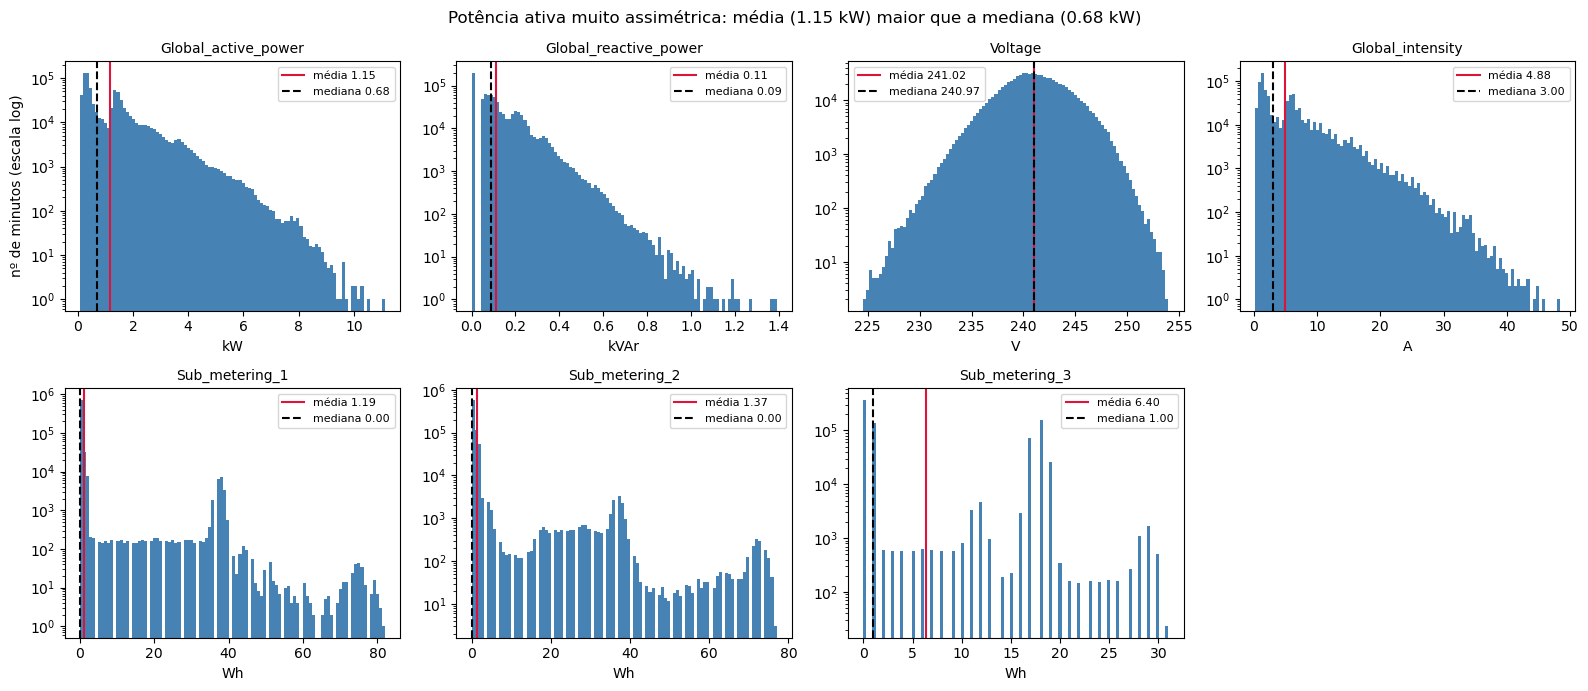

,n,lim_inf_IQR,lim_sup_IQR,MAD_norm,outliers_IQR,%IQR,outliers_z,%z,ambos
Global_active_power,788913.0,-1.592,3.496,0.703,38883.0,4.929,51172.0,6.486,38883.0
Global_reactive_power,788913.0,-0.255,0.425,0.128,11481.0,1.455,3596.0,0.456,3596.0
Voltage,788913.0,232.985,249.105,2.980,9391.0,1.190,1249.0,0.158,1249.0
Global_intensity,788913.0,-6.400,14.400,3.262,42484.0,5.385,41010.0,5.198,41010.0
Sub_metering_1,788913.0,0.000,0.000,0.000,66429.0,8.420,NaN,NaN,NaN
Sub_metering_2,788913.0,-1.500,2.500,0.000,32304.0,4.095,NaN,NaN,NaN
Sub_metering_3,788913.0,-25.500,42.500,1.483,0.0,0.000,277591.0,35.187,0.0



Submedições — só minutos em uso (> 0):
  Sub_metering_1: minutos em uso = 66,429 (8.4%) | outliers IQR: 0.0% | z robusto: 37.8%
  Sub_metering_2: minutos em uso = 199,595 (25.3%) | outliers IQR: 14.7% | z robusto: 0.0%
  Sub_metering_3: minutos em uso = 415,407 (52.7%) | outliers IQR: 0.0% | z robusto: 35.6%
Outliers de potência: IQR 38,883 | z robusto 51,172 | ambos 38,883 (analisados a seguir)


,minutos,%
categoria,,
evento real sustentado,30305,77.9
pico isolado (verificar),8062,20.7
evento sustentado s/ submedição (investigar),516,1.3



Os 10 eventos de outliers com maior energia:


,inicio,dur_min,P_media_kW,P_max_kW,kWh,sub_share
evento,,,,,,
1646,2008-01-12 22:35:00,185,4.30,6.92,13.26,0.31
4667,2008-11-23 17:30:00,118,5.43,7.72,10.67,0.35
1859,2008-01-26 18:58:00,120,5.26,9.67,10.52,0.42
4261,2008-10-19 00:00:00,98,6.03,10.29,9.85,0.46
5289,2009-01-16 19:25:00,91,6.46,8.11,9.80,0.64
1378,2007-12-28 16:07:00,95,5.93,9.59,9.39,0.54
1045,2007-12-09 17:45:00,115,4.64,6.34,8.90,0.40
2434,2008-03-13 20:23:00,87,5.67,7.78,8.22,0.60
4668,2008-11-23 19:52:00,83,5.86,8.56,8.11,0.42


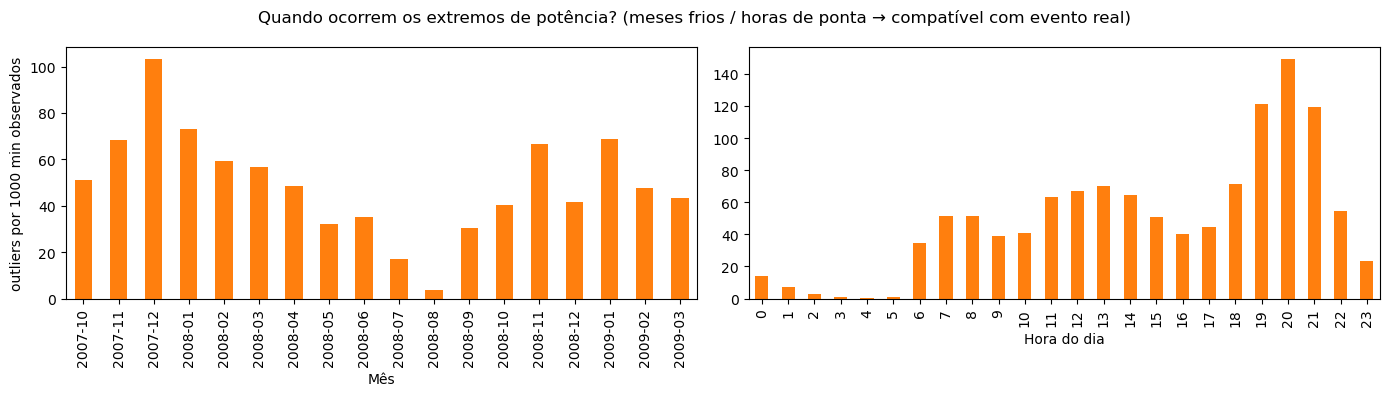

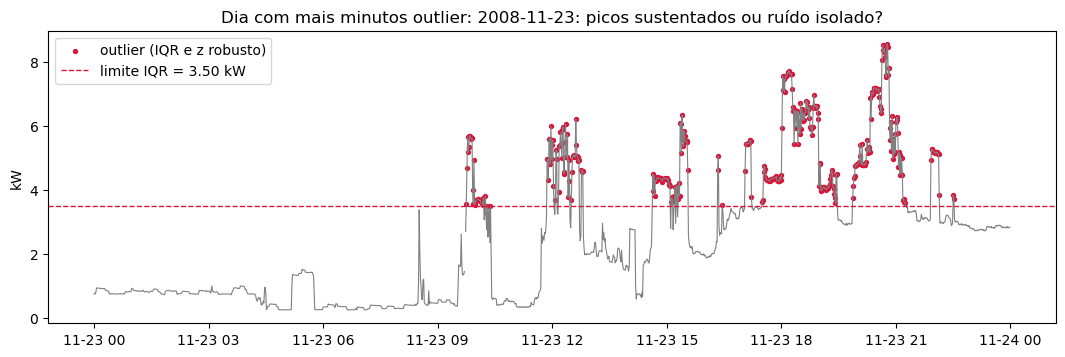

548 dias com cobertura ≥ 80% | mediana diária 27.9 kWh | MAD norm 8.9 kWh

5 dias de consumo mais ALTO:


,kWh_dia,z_robusto,dia_semana,cobertura
Datetime,,,,
2008-11-23,56.79,3.26,Sunday,1.0
2009-01-17,55.30,3.09,Saturday,1.0
2009-01-31,55.21,3.08,Saturday,1.0
2007-12-29,54.98,3.06,Saturday,1.0
2008-11-24,53.55,2.89,Monday,1.0


5 dias de consumo mais BAIXO:


,kWh_dia,z_robusto,dia_semana,cobertura
Datetime,,,,
2008-08-25,4.17,-2.68,Monday,1.0
2008-08-23,4.24,-2.68,Saturday,1.0
2008-08-24,4.25,-2.68,Sunday,1.0
2008-08-26,4.29,-2.67,Tuesday,1.0
2008-08-27,4.30,-2.67,Wednesday,1.0


5 dias com MENOR variabilidade intra-dia (dp):


,kWh_dia,dp,dia_semana
Datetime,,,
2008-08-26,4.293,0.131,Tuesday
2008-08-23,4.244,0.132,Saturday
2008-08-25,4.172,0.132,Monday
2008-08-24,4.245,0.133,Sunday
2008-08-21,4.355,0.139,Thursday


mediana (kW)                                     IQR (kW)              \
              Seg   Ter   Qua   Qui   Sex   Sáb   Dom      Seg   Ter   Qua   
hora                                                                         
0            0.35  0.34  0.34  0.33  0.33  0.37  0.76     0.19  0.34  0.21   
1            0.33  0.32  0.32  0.32  0.31  0.33  0.53     0.16  0.16  0.16   
2            0.32  0.32  0.31  0.31  0.31  0.32  0.42     0.16  0.17  0.16   
3            0.32  0.32  0.31  0.31  0.31  0.32  0.35     0.17  0.17  0.16   
4            0.32  0.32  0.31  0.31  0.31  0.31  0.34     0.18  0.16  0.16   
5            0.31  0.30  0.31  0.31  0.31  0.32  0.32     0.16  0.16  0.18   
6            0.38  0.38  0.41  0.42  0.38  0.33  0.32     1.07  1.10  1.15   
7            1.87  1.84  1.94  1.78  1.90  0.74  0.32     1.84  1.35  1.18   
8            1.41  1.48  1.48  1.54  1.59  1.46  0.41     0.59  0.75  0.64   
9            1.38  1.38  1.39  1.38  1.38  1.40  0.65     0.29  0.77  0.28   
10           1.37  1.36  1.38  1.34  1.39  1.43  0.87     0.85  1.21  0.90   
11           1.33  1.39  1.35  1.28  1.37  1.48  1.24     1.02  1.36  1.13   
12           1.31  1.40  1.25  0.70  1.37  1.46  1.46     1.14  1.45  1.23   
13           0.53  1.42  0.72  0.41  1.37  1.52  1.50     1.11  1.73  1.17   
14           0.43  1.38  0.51  0.41  1.30  1.46  1.50     1.05  1.28  1.24   
15           0.41  1.38  0.43  0.38  0.74  1.35  1.36     0.62  1.23  1.08   
16           0.41  0.84  0.41  0.37  0.63  1.33  0.93     0.40  1.22  1.01   
17           0.44  0.68  0.64  0.40  0.99  1.44  1.10     0.56  1.17  1.17   
18           0.63  1.11  0.98  0.67  1.35  1.77  1.59     1.08  1.30  1.63   
19           1.44  1.54  1.57  1.63  1.59  2.26  2.14     1.86  1.74  1.86   
20           1.76  1.78  1.72  2.08  1.66  1.89  2.30     1.71  1.45  1.89   
21           1.79  1.79  1.95  1.71  1.62  1.66  2.08     1.45  1.40  1.75   
22           1.06  1.41  1.23  0.98  1.15  1.53  1.03     1.33  1.66  1.41   
23           0.42  0.42  0.40  0.42  0.50  1.29  0.42     0.97  0.80  0.58   

      ...     n             cobertura (%)                                  \
      ...   Sex   Sáb   Dom           Seg     Ter     Qua     Qui     Sex   
hora  ...                                                                   
0     ...  4680  4680  4680        100.00  100.00  100.00  100.00  100.00   
1     ...  4680  4680  4680        100.00  100.00  100.00  100.00  100.00   
2     ...  4680  4680  4680        100.00  100.00  100.00   99.98  100.00   
3     ...  4680  4680  4680        100.00  100.00  100.00  100.00  100.00   
4     ...  4680  4680  4680        100.00  100.00  100.00  100.00  100.00   
5     ...  4680  4680  4680        100.00  100.00  100.00  100.00  100.00   
6     ...  4680  4680  4680        100.00  100.00  100.00  100.00  100.00   
7     ...  4680  4680  4680        100.00  100.00  100.00  100.00  100.00   
8     ...  4680  4680  4680        100.00  100.00  100.00  100.00  100.00   
9     ...  4680  4678  4679        100.00  100.00  100.00  100.00  100.00   
10    ...  4680  4646  4680        100.00   99.49   99.74  100.00  100.00   
11    ...  4680  4669  4680        100.00  100.00   98.76  100.00  100.00   
12    ...  4680  4680  4680        100.00  100.00  100.00  100.00  100.00   
13    ...  4680  4680  4680         99.98  100.00  100.00  100.00  100.00   
14    ...  4680  4679  4680        100.00  100.00   99.96  100.00  100.00   
15    ...  4680  4680  4679        100.00  100.00  100.00  100.00  100.00   
16    ...  4680  4679  4649        100.00  100.00  100.00  100.00  100.00   
17    ...  4680  4680  4673         99.85  100.00  100.00  100.00  100.00   
18    ...  4679  4680  4679        100.00  100.00  100.00  100.00   99.98   
19    ...  4678  4680  4679        100.00  100.00  100.00  100.00   99.96   
20    ...  4680  4680  4678        100.00  100.00  100.00  100.00  100.00   
21    ...  4680  4680  4680         99.98   99.96 

Células hora × dia com cobertura < 80%: 0 de 168


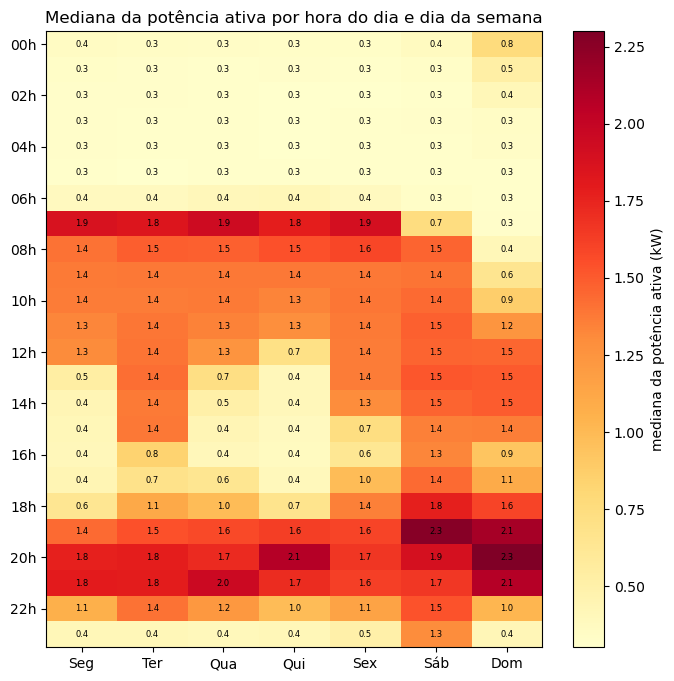

In [10]:
# %% [markdown]
# # 1.3 Sumário estatístico com juízo
# Células para colar no notebook, a seguir à célula `df_tratado = tratar_missing(...)`.
# Usam `df_tratado`, `inicio` e `fim` que já tens. Imports necessários: pandas, numpy, matplotlib (já importados)
# e `from scipy import stats` (primeira célula abaixo).

# %%
from scipy import stats

VARS = ["Global_active_power", "Global_reactive_power", "Voltage", "Global_intensity",
        "Sub_metering_1", "Sub_metering_2", "Sub_metering_3"]
UNIDADES = {"Global_active_power": "kW", "Global_reactive_power": "kVAr", "Voltage": "V",
            "Global_intensity": "A", "Sub_metering_1": "Wh", "Sub_metering_2": "Wh", "Sub_metering_3": "Wh"}
Z_LIMIAR = 3.5        # limiar do z-score robusto (Iglewicz-Hoaglin)
SUSTENTADO_MIN = 5    # outlier "sustentado" = >= 5 minutos consecutivos
TOL_P_S = 1.05        # P/S acima disto é fisicamente incoerente (S = V*I)


def valores_observados(df_tratado):
    """Só valores realmente medidos: os minutos imputados passam a NaN.
    (O sumário e os outliers não devem depender do método de imputação: médias e valores aleatórios
    alteram a variância e podem criar/esconder extremos.)"""
    return df_tratado[VARS].where(~df_tratado["imputado"])


obs = valores_observados(df_tratado)
print(f"Minutos observados (não imputados) em Global_active_power: {obs['Global_active_power'].notna().sum():,} "
      f"de {len(obs):,}")

# %% [markdown]
# ## (a) Localização e dispersão: média vs mediana (com a assimetria a justificar)

# %%
def sumario_estatistico(obs):
    def um(s):
        s = s.dropna().astype("float64")
        q1, med, q3 = s.quantile([.25, .5, .75])
        skew = s.skew()
        return pd.Series({
            "n": len(s), "média": s.mean(), "mediana": med, "dp": s.std(),
            "MAD_norm": stats.median_abs_deviation(s, scale="normal"), "IQR": q3 - q1,
            "assimetria": skew, "curtose_exc": s.kurt(), "min": s.min(), "p1": s.quantile(.01),
            "p99": s.quantile(.99), "max": s.max(), "%zeros": (s == 0).mean() * 100,
            "recomendação": "mediana + IQR" if abs(skew) > 1 else "média + dp"})
    tab = pd.DataFrame({v: um(obs[v]) for v in VARS}).T
    tab.insert(0, "unidade", [UNIDADES[v] for v in tab.index])
    num = tab.columns.difference(["unidade", "recomendação"])
    tab[num] = tab[num].astype(float).round(3)
    print("Regra: |assimetria| > 1 → distribuição muito assimétrica → mediana + IQR (robustos); senão média + dp.")
    display(tab)
    return tab


def grafico_distribuicoes(obs):
    fig, axes = plt.subplots(2, 4, figsize=(16, 7))
    for ax, v in zip(axes.ravel(), VARS):
        s = obs[v].dropna()
        ax.hist(s, bins=100, color="steelblue", log=True)
        ax.axvline(s.mean(), color="crimson", lw=1.5, label=f"média {s.mean():.2f}")
        ax.axvline(s.median(), color="black", ls="--", lw=1.5, label=f"mediana {s.median():.2f}")
        ax.set_title(v, fontsize=10); ax.set_xlabel(UNIDADES[v]); ax.legend(fontsize=8)
    axes.ravel()[-1].axis("off")
    axes[0, 0].set_ylabel("nº de minutos (escala log)")
    p = obs["Global_active_power"].dropna()
    fig.suptitle(f"Potência ativa muito assimétrica: média ({p.mean():.2f} kW) maior que a mediana ({p.median():.2f} kW)")
    fig.tight_layout()
    plt.show()


tab_sumario = sumario_estatistico(obs)
grafico_distribuicoes(obs)

# %% [markdown]
# ## (b) Outliers: regra 1.5×IQR e z-score robusto (mediana/MAD)
# Nas submedições a maioria dos minutos é 0: MAD = 0 (z-score robusto indefinido) e Q1 = Q3 = 0 (qualquer valor > 0 é "outlier" pelo IQR).
# Por isso repete-se a análise só nos minutos "em uso" (> 0).

# %%
def outliers(s, z_lim=Z_LIMIAR):
    s = s.dropna().astype("float64")
    q1, q3 = s.quantile([.25, .75])
    lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    f_iqr = (s < lo) | (s > hi)
    mad = stats.median_abs_deviation(s, scale="normal")
    z = (s - s.median()) / mad if mad > 0 else pd.Series(np.nan, index=s.index)
    f_z = z.abs() > z_lim
    return f_iqr, f_z, lo, hi, mad


def tabela_outliers(obs):
    linhas = {}
    for v in VARS:
        f_iqr, f_z, lo, hi, mad = outliers(obs[v])
        ok = mad > 0
        linhas[v] = {"n": len(f_iqr), "lim_inf_IQR": lo, "lim_sup_IQR": hi, "MAD_norm": mad,
                     "outliers_IQR": int(f_iqr.sum()), "%IQR": 100 * f_iqr.mean(),
                     "outliers_z": int(f_z.sum()) if ok else np.nan, "%z": 100 * f_z.mean() if ok else np.nan,
                     "ambos": int((f_iqr & f_z).sum()) if ok else np.nan}
    tab = pd.DataFrame(linhas).T.round(3)
    display(tab)

    print("\nSubmedições — só minutos em uso (> 0):")
    for v in ["Sub_metering_1", "Sub_metering_2", "Sub_metering_3"]:
        s = obs[v].dropna(); s = s[s > 0]
        f_iqr, f_z, *_ = outliers(s)
        print(f"  {v}: minutos em uso = {len(s):,} ({len(s) / obs[v].notna().sum():.1%}) | "
              f"outliers IQR: {f_iqr.mean():.1%} | z robusto: {f_z.mean():.1%}")
    return tab


tab_out = tabela_outliers(obs)

# %% [markdown]
# ## (c) Investigação dos extremos de potência ativa: erro, evento real ou suspeito?
# Cada minuto outlier (IQR **e** z robusto) é classificado:
# - **erro provável**: fisicamente incoerente (P > S = V·I/1000 acima da tolerância) ou tensão fora de 190–270 V;
# - **evento sustentado**: ≥ 5 min consecutivos. Se as submedições explicam < 20% da energia → "investigar" (carga não medida; **hipótese**, não prova, de fraude);
# - **pico isolado**: < 5 min, a verificar.

# %%
def runs_true(mask):
    m = np.concatenate(([0], mask.to_numpy().astype(np.int8), [0]))
    d = np.diff(m)
    ini, fim_ = np.flatnonzero(d == 1), np.flatnonzero(d == -1)
    return ini, fim_


def investigar_outliers(obs):
    P = obs["Global_active_power"]
    f_iqr, f_z, lo, hi, mad = outliers(P)
    cons = (f_iqr & f_z).reindex(P.index, fill_value=False)           # consenso das duas regras
    print(f"Outliers de potência: IQR {int(f_iqr.sum()):,} | z robusto {int(f_z.sum()):,} | "
          f"ambos {int(cons.sum()):,} (analisados a seguir)")

    ini, fim_ = runs_true(cons)
    dur = fim_ - ini
    o = obs.loc[cons].copy()
    o["evento"] = np.repeat(np.arange(len(ini)), dur)
    o["dur_evento"] = np.repeat(dur, dur)
    o["E_Wh"] = o["Global_active_power"] * 1000 / 60
    o["sub_sum"] = o[["Sub_metering_1", "Sub_metering_2", "Sub_metering_3"]].sum(axis=1, min_count=1)
    o["sub_share"] = o["sub_sum"] / o["E_Wh"]
    S = o["Voltage"] * o["Global_intensity"] / 1000
    o["P_sobre_S"] = o["Global_active_power"] / S.where(S > 0)

    erro = (o["P_sobre_S"] > TOL_P_S) | (o["Voltage"] < 190) | (o["Voltage"] > 270)
    sust = o["dur_evento"] >= SUSTENTADO_MIN
    nao_expl = o["sub_share"] < 0.2
    o["categoria"] = np.select(
        [erro, sust & nao_expl, sust],
        ["erro provável", "evento sustentado s/ submedição (investigar)", "evento real sustentado"],
        default="pico isolado (verificar)")
    cat = o["categoria"].value_counts().to_frame("minutos")
    cat["%"] = (100 * cat["minutos"] / cat["minutos"].sum()).round(1)
    display(cat)

    g = o.groupby("evento")
    ev = pd.DataFrame({
        "inicio": o.index.to_series().groupby(o["evento"]).min(),
        "dur_min": g.size(),
        "P_media_kW": g["Global_active_power"].mean(),
        "P_max_kW": g["Global_active_power"].max(),
        "kWh": g["Global_active_power"].sum() / 60,
        "sub_share": g["sub_sum"].sum() / g["E_Wh"].sum()})
    print("\nOs 10 eventos de outliers com maior energia:")
    display(ev.nlargest(10, "kWh").round({c: 2 for c in ev.columns if c != "inicio"}))

    # Quando acontecem? (por 1000 minutos observados, para compensar meses/horas com mais falhas)
    ob = P.notna()
    por_mes = (o.groupby(o.index.to_period("M")).size() / ob.groupby(ob.index.to_period("M")).sum() * 1000).fillna(0)
    por_hora = (o.groupby(o.index.hour).size() / ob.groupby(ob.index.hour).sum() * 1000).reindex(range(24), fill_value=0)
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    por_mes.plot(kind="bar", ax=axes[0], color="tab:orange"); axes[0].set_xlabel("Mês"); axes[0].set_ylabel("outliers por 1000 min observados")
    por_hora.plot(kind="bar", ax=axes[1], color="tab:orange"); axes[1].set_xlabel("Hora do dia")
    fig.suptitle("Quando ocorrem os extremos de potência? (meses frios / horas de ponta → compatível com evento real)")
    fig.tight_layout(); plt.show()

    # Dia com mais minutos outlier, em contexto
    if len(o):
        dia_top = o.index.normalize().value_counts().idxmax()
        dia = P.loc[dia_top:dia_top + pd.Timedelta(days=1) - pd.Timedelta(minutes=1)]
        fig, ax = plt.subplots(figsize=(13, 3.8))
        ax.plot(dia.index, dia.values, lw=0.8, color="gray")
        pts = dia[cons.loc[dia.index]]
        ax.scatter(pts.index, pts.values, s=8, color="crimson", label="outlier (IQR e z robusto)")
        ax.axhline(hi, color="crimson", ls="--", lw=1, label=f"limite IQR = {hi:.2f} kW")
        ax.set_ylabel("kW"); ax.legend()
        ax.set_title(f"Dia com mais minutos outlier: {dia_top:%Y-%m-%d}: picos sustentados ou ruído isolado?")
        plt.show()
    return o, ev


outl, eventos = investigar_outliers(obs)

# %% [markdown]
# ### Extremos ao nível do dia (lado alto e lado baixo)
# Dias muito baixos = ausências/férias ou falha parcial. Dias com variabilidade intra-dia anormalmente baixa e consumo > 0
# podem sugerir leituras "presas" (a investigar, não a concluir).

# %%
def extremos_diarios(obs, cobertura_min=0.8):
    P = obs["Global_active_power"]
    d = P.resample("D").agg(media="mean", dp="std", n="count")
    d["cobertura"] = d["n"] / 1440
    d = d[d["cobertura"] >= cobertura_min].copy()
    d["kWh_dia"] = d["media"] * 24
    m = d["kWh_dia"].median(); mad = stats.median_abs_deviation(d["kWh_dia"], scale="normal")
    d["z_robusto"] = (d["kWh_dia"] - m) / mad
    d["dia_semana"] = d.index.day_name()
    print(f"{len(d)} dias com cobertura ≥ {cobertura_min:.0%} | mediana diária {m:.1f} kWh | MAD norm {mad:.1f} kWh")
    cols = ["kWh_dia", "z_robusto", "dia_semana", "cobertura"]
    print("\n5 dias de consumo mais ALTO:"); display(d.nlargest(5, "kWh_dia")[cols].round(2))
    print("5 dias de consumo mais BAIXO:"); display(d.nsmallest(5, "kWh_dia")[cols].round(2))
    print("5 dias com MENOR variabilidade intra-dia (dp):"); display(d.nsmallest(5, "dp")[["kWh_dia", "dp", "dia_semana"]].round(3))
    return d


diario = extremos_diarios(obs)

# %% [markdown]
# ## (d) Sumário estratificado: hora do dia × dia da semana (com n)
# Mediana e IQR (distribuição muito assimétrica), n de minutos válidos e cobertura face ao esperado.
# **Cuidado:** 18 meses repetem uns meses do ano e outros não, por isso este quadro mistura sazonalidade anual com o padrão semanal.

# %%
def sumario_estratificado(obs, inicio, fim):
    DIAS = ["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"]
    P = obs["Global_active_power"]
    grp = P.groupby([P.index.hour.rename("hora"), P.index.dayofweek.rename("dia_semana")])
    est = pd.DataFrame({"n": grp.count(), "q1": grp.quantile(.25), "mediana": grp.median(), "q3": grp.quantile(.75)})
    est["IQR"] = est["q3"] - est["q1"]
    dias_na_janela = pd.date_range(inicio, fim - pd.Timedelta(days=1), freq="D")
    n_dias_sem = pd.Series(dias_na_janela.dayofweek).value_counts().sort_index()
    est["cobertura_%"] = est["n"] / (est.index.get_level_values("dia_semana").map(n_dias_sem) * 60) * 100

    piv = pd.concat({"mediana (kW)": est["mediana"].unstack("dia_semana"),
                     "IQR (kW)": est["IQR"].unstack("dia_semana"),
                     "n": est["n"].unstack("dia_semana"),
                     "cobertura (%)": est["cobertura_%"].unstack("dia_semana")}, axis=1)
    piv.columns = pd.MultiIndex.from_tuples([(a, DIAS[b]) for a, b in piv.columns])
    display(piv.round(2))
    print(f"Células hora × dia com cobertura < 80%: {(est['cobertura_%'] < 80).sum()} de {len(est)}")

    med = est["mediana"].unstack("dia_semana"); med.columns = DIAS
    fig, ax = plt.subplots(figsize=(8, 8))
    im = ax.imshow(med.values, aspect="auto", cmap="YlOrRd")
    ax.set_xticks(range(7), labels=DIAS)
    ax.set_yticks(range(0, 24, 2), labels=[f"{h:02d}h" for h in range(0, 24, 2)])
    for i in range(24):
        for j in range(7):
            ax.text(j, i, f"{med.values[i, j]:.1f}", ha="center", va="center", fontsize=6)
    fig.colorbar(im, ax=ax, label="mediana da potência ativa (kW)")
    ax.set_title("Mediana da potência ativa por hora do dia e dia da semana")
    plt.show()
    return piv


piv_hora_dia = sumario_estratificado(obs, inicio, fim)